# 1 Configuração e Implementação dos Módulos

In [1]:
import os
import sys
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Adiciona o diretório 'src' ao caminho do Python para importar os scripts do projeto
sys.path.append("../src")

from dataset import carregar_caminhos_dataset
from preprocessing import (
    aplicar_clahe,
    converter_para_cinza,
    preprocessar_imagem,
    remover_ruido,
)
from segmentation import (
    aplicar_morfologia,
    binarizar_otsu,
    extrair_maior_componente_e_roi,
)

print("Módulos e dependências carregados com sucesso!")

Módulos e dependências carregados com sucesso!


# 2: Mapeamento e Seleção de Amostras do Dataset

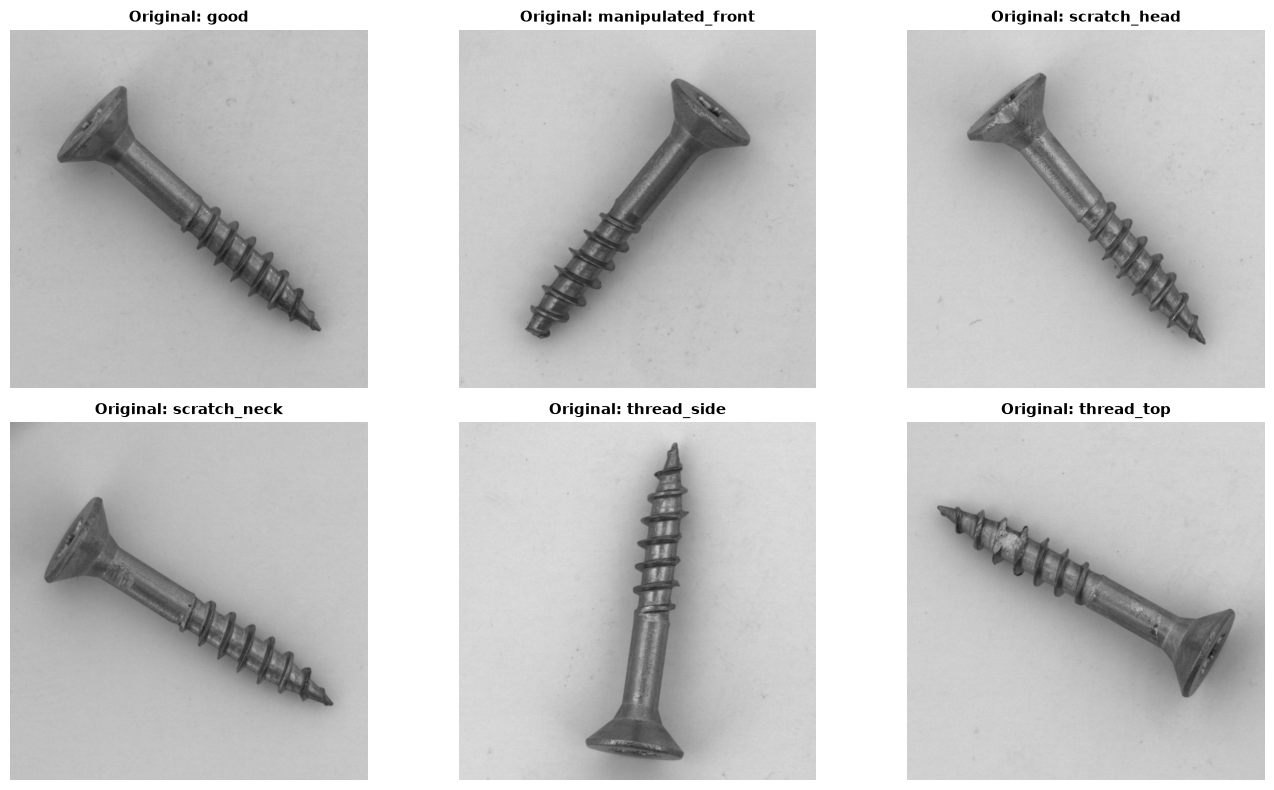

In [2]:
# Carrega a estrutura do dataset apontando para a pasta 'data' na raiz
df = carregar_caminhos_dataset(data_dir="../data")

# Lista das 6 categorias do conjunto de teste
categorias = [
    "good",
    "manipulated_front",
    "scratch_head",
    "scratch_neck",
    "thread_side",
    "thread_top",
]

# Seleciona a primeira imagem encontrada para cada categoria de teste
amostras = {}
for cat in categorias:
    df_cat = df[(df["split"] == "test") & (df["classe"] == cat)]
    if not df_cat.empty:
        amostras[cat] = df_cat.iloc[0]["caminho"]

# Exibe o grid com as imagens originais em RGB
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for i, (cat, caminho) in enumerate(amostras.items()):
    img_bgr = cv2.imread(caminho)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    axes[i].imshow(img_rgb)
    axes[i].set_title(f"Original: {cat}", fontsize=11, fontweight="bold")
    axes[i].axis("off")

plt.tight_layout()
plt.show()



# 3: Conversão para Escala de Cinza

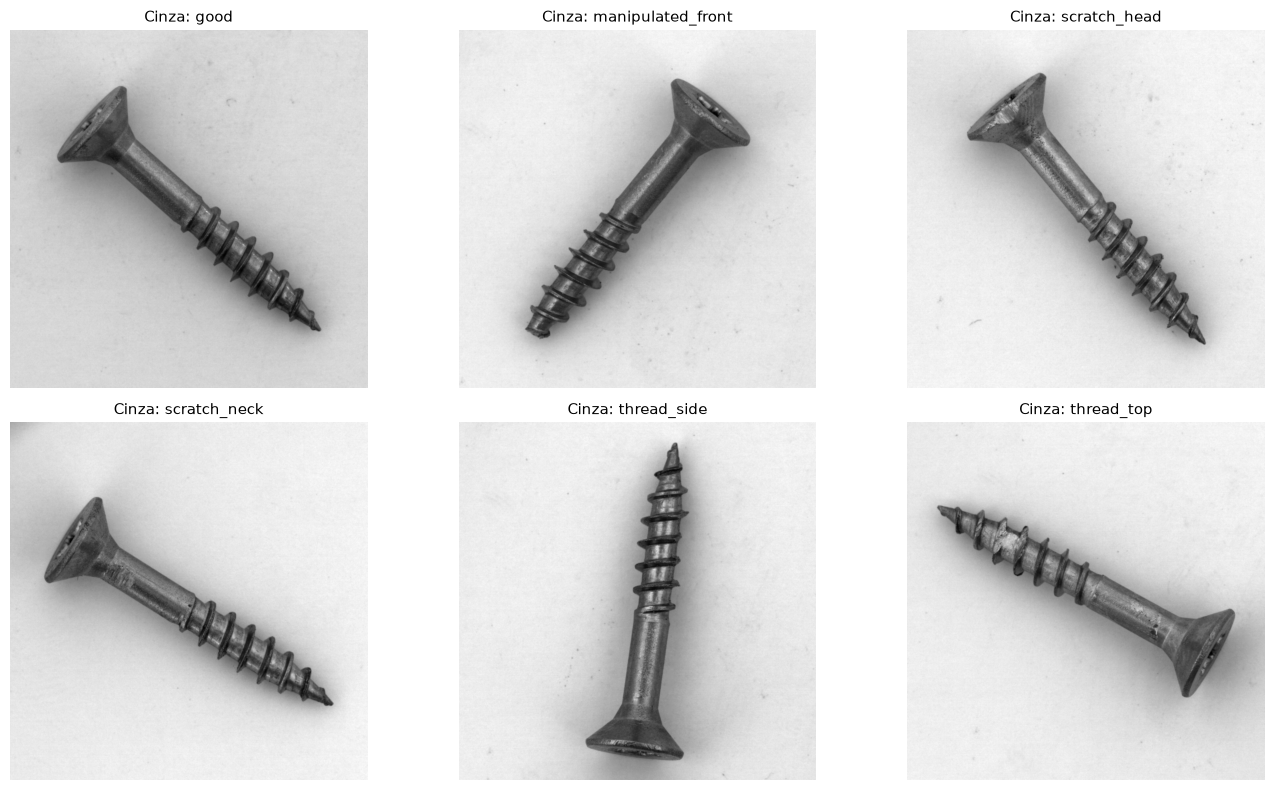

In [3]:
imgs_cinza = {}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for i, (cat, caminho) in enumerate(amostras.items()):
    img_bgr = cv2.imread(caminho)
    cinza = converter_para_cinza(img_bgr)
    imgs_cinza[cat] = cinza
    
    axes[i].imshow(cinza, cmap="gray")
    axes[i].set_title(f"Cinza: {cat}", fontsize=11)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


# 4: Equalização Adaptativa CLAHE

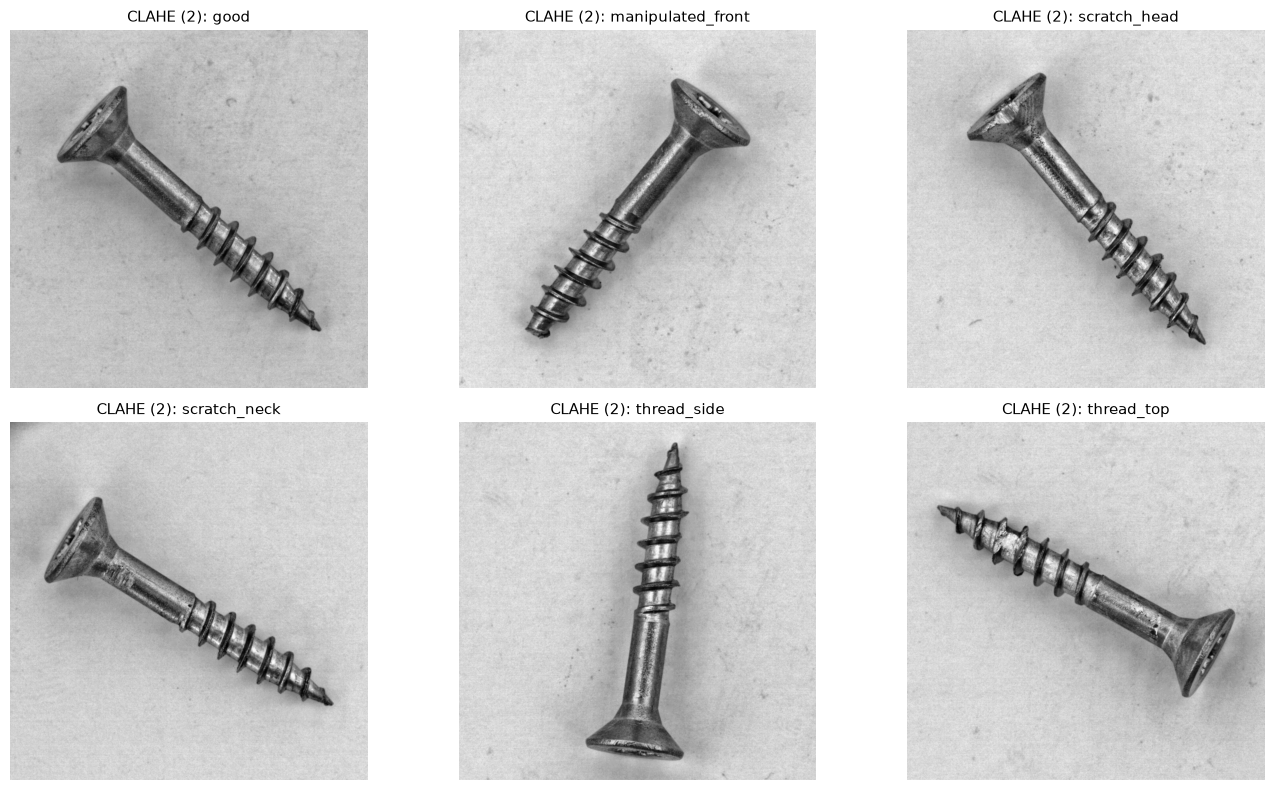

In [46]:
# === AJUSTE OS PARÂMETROS AQUI ===
CLIP_LIMIT = 2
TILE_SIZE = (20, 20)

imgs_clahe = {}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for i, (cat, cinza) in enumerate(imgs_cinza.items()):
    clahe = aplicar_clahe(
        cinza, clip_limit=CLIP_LIMIT, tile_grid_size=TILE_SIZE
    )
    imgs_clahe[cat] = clahe
    
    axes[i].imshow(clahe, cmap="gray")
    axes[i].set_title(f"CLAHE ({CLIP_LIMIT}): {cat}", fontsize=11)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


# 5: Binarização por Limiarização de Otsu

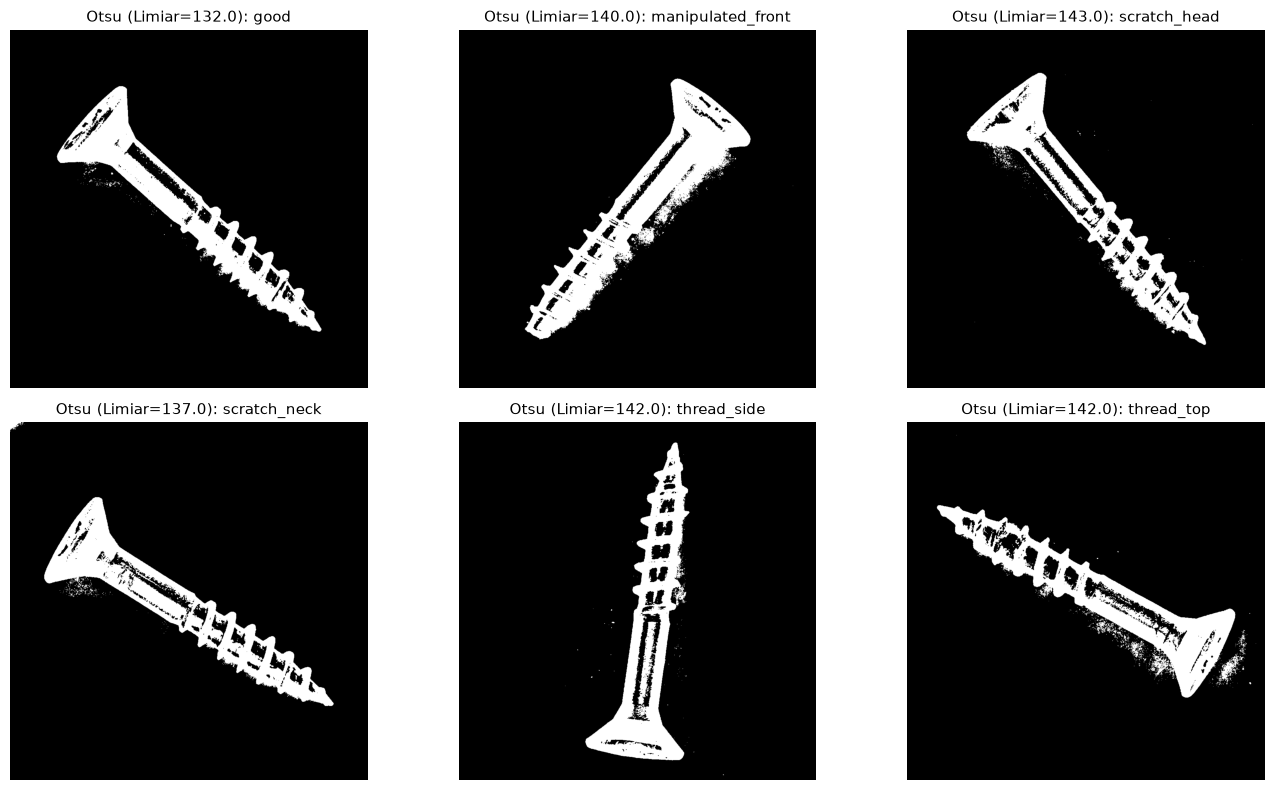

In [47]:
imgs_otsu = {}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for i, (cat, clahe) in enumerate(imgs_clahe.items()):
    limiar, mascara = binarizar_otsu(clahe, inverter=True)
    imgs_otsu[cat] = mascara
    
    axes[i].imshow(mascara, cmap="gray")
    axes[i].set_title(f"Otsu (Limiar={limiar:.1f}): {cat}", fontsize=11)
    axes[i].axis("off")

plt.tight_layout()
plt.show()



# 6: Morfologia Matemática (Abertura e Fechamento)

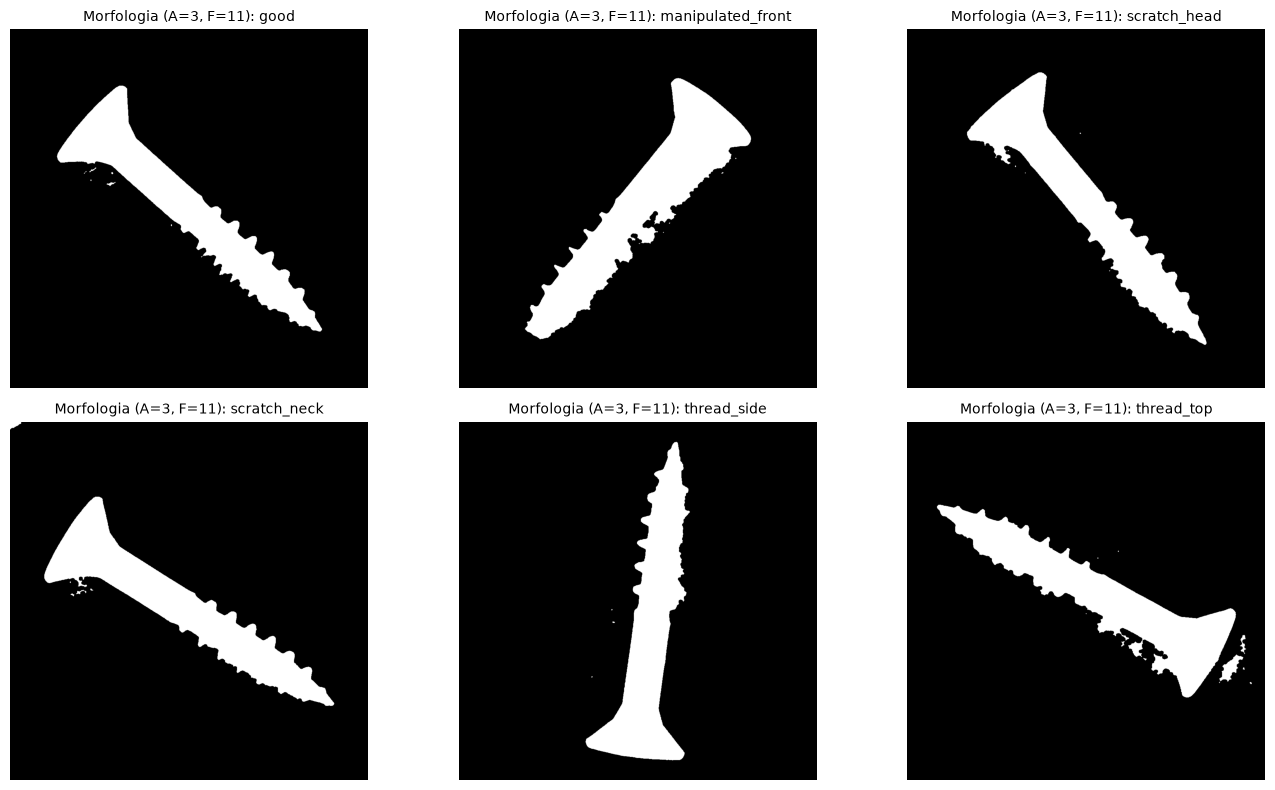

In [53]:
# === AJUSTE OS PARÂMETROS AQUI ===
TAMANHO_ABERTURA = 3
TAMANHO_FECHAMENTO = 11

imgs_morfologia = {}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for i, (cat, mascara) in enumerate(imgs_otsu.items()):
    mascara_limpa = aplicar_morfologia(
        mascara,
        tamanho_abertura=TAMANHO_ABERTURA,
        tamanho_fechamento=TAMANHO_FECHAMENTO,
        preencher_lacunas = True
    )
    imgs_morfologia[cat] = mascara_limpa
    
    axes[i].imshow(mascara_limpa, cmap="gray")
    axes[i].set_title(f"Morfologia (A={TAMANHO_ABERTURA}, F={TAMANHO_FECHAMENTO}): {cat}", fontsize=10)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


# 7: Recorte e Alinhamento da Região de Interesse (ROI)

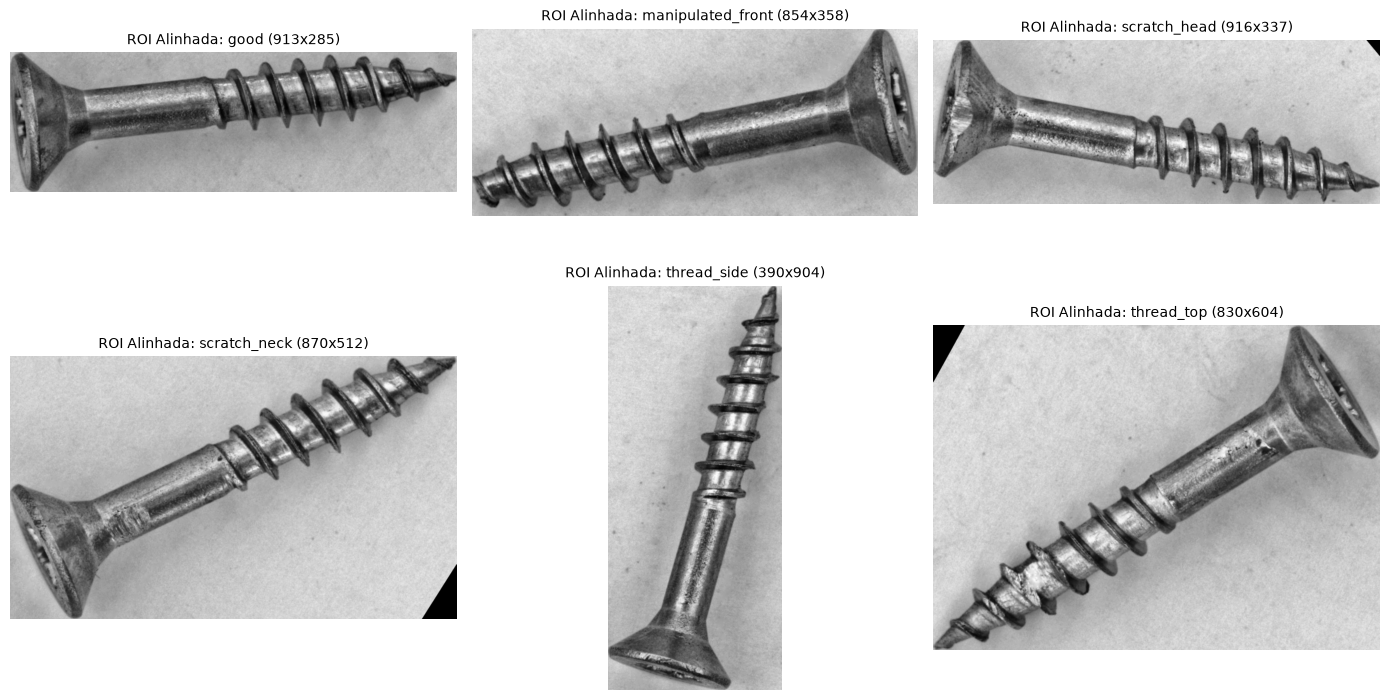

In [49]:
imgs_roi = {}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for i, (cat, mascara_limpa) in enumerate(imgs_morfologia.items()):
    clahe = imgs_clahe[cat]
    roi_img, roi_mask, _ = extrair_maior_componente_e_roi(
        clahe, mascara_limpa, alinhar_eixo=True
    )
    imgs_roi[cat] = roi_img
    
    axes[i].imshow(roi_img, cmap="gray")
    axes[i].set_title(
        f"ROI Alinhada: {cat} ({roi_img.shape[1]}x{roi_img.shape[0]})",
        fontsize=10,
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()
